In [1]:
from pathlib import Path
import copy, json, os, random, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights

DEVICE = torch.device("cuda")
GPU_NAME = torch.cuda.get_device_name(0)

print("GPU:", GPU_NAME)

C:\Users\elesh\Academics\UTS\36127InnovationLab\Development\AutoVision_Model_Development\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


GPU: NVIDIA GeForce RTX 5060 Laptop GPU


## 1. Confirming CUDA is being used and setting up reproducibility and project paths

In [2]:
print("PyTorch:", torch.__version__)
print("CUDA runtime:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "None")

SEED = 42

def reset_seed():
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

def find_project_root(start=None):
    start = (start or Path.cwd()).resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "pyproject.toml").exists():
            return candidate
    raise FileNotFoundError("Could not find pyproject.toml.")

PROJECT_ROOT = find_project_root()
DATA_DIR = PROJECT_ROOT / "data"
MODEL_DIR = PROJECT_ROOT / "models" / "efficientnet_b0_hparam"
REPORT_DIR = PROJECT_ROOT / "reports" / "efficientnet_b0_hparam"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)
print("Project root:", PROJECT_ROOT)

PyTorch: 2.14.0+cu130
CUDA runtime: 13.0
CUDA available: True
GPU: NVIDIA GeForce RTX 5060 Laptop GPU
Project root: C:\Users\elesh\Academics\UTS\36127InnovationLab\Development\AutoVision_Model_Development


## 2. Loading dataset split

In [3]:
df = pd.read_csv(
    DATA_DIR / "interim" / "compcars_resnet50_baseline_split.csv"
)

train_df = df[df["split"] == "train"].copy()
val_df = df[df["split"] == "val"].copy()
test_df = df[df["split"] == "test"].copy()

NUM_CLASSES = df["target"].nunique()

class_names = (
    df[["target", "class_name"]]
    .drop_duplicates()
    .sort_values("target")["class_name"]
    .tolist()
)

print("Rows:", len(df))
print("Classes:", NUM_CLASSES)
print("Train / Val / Test:", len(train_df), len(val_df), len(test_df))

Rows: 2000
Classes: 20
Train / Val / Test: 1600 200 200


## 3. Configuring CompCars path

In [5]:
DEFAULT_COMPCARS = (
    r"G:\.shortcut-targets-by-id\1OOvt005TduvEA8h6_snfuyQtbQAjo-3J"
    r"\capstone-vehicle-metadata\data\compcars_kaggle\extracted"
)

ROOT = Path(
    os.environ.get("COMPCARS_EXTRACTED", DEFAULT_COMPCARS)
)

if not ROOT.exists():
    raise FileNotFoundError(
        f"CompCars path does not exist:\n{ROOT}"
    )

def resolve_local_path(original_path):
    text = str(original_path).replace("\\", "/")

    if "/extracted/" in text:
        relative = text.split("/extracted/", 1)[1]
    elif "/image/" in text:
        relative = "image/" + text.split("/image/", 1)[1]
    else:
        return Path(original_path)

    return ROOT / Path(*relative.split("/"))

for part in [train_df, val_df, test_df]:
    part["local_file_path"] = part["file_path"].map(
        resolve_local_path
    )

sample = pd.concat(
    [train_df, val_df, test_df]
).sample(30, random_state=SEED)

if not sample["local_file_path"].map(Path.exists).all():
    raise FileNotFoundError("Some image paths do not resolve.")

print("Image path mapping is good.")

Image path mapping is good.


## 4. Hyperparameter configurations

In [6]:
EXPERIMENTS = [
    {
        "name":"corrected_baseline",
        "finetune_lr":1e-4,
        "weight_decay":1e-4,
        "unfreeze_depth":"last_stage",
        "label_smoothing":0.1,
        "augmentation":"standard",
        "stage2_epochs":5,
    },
    {
        "name":"lr_5e-5",
        "finetune_lr":5e-5,
        "weight_decay":1e-4,
        "unfreeze_depth":"last_stage",
        "label_smoothing":0.1,
        "augmentation":"standard",
        "stage2_epochs":5,
    },
    {
        "name":"lr_5e-4",
        "finetune_lr":5e-4,
        "weight_decay":1e-4,
        "unfreeze_depth":"last_stage",
        "label_smoothing":0.1,
        "augmentation":"standard",
        "stage2_epochs":5,
    },
    {
        "name":"unfreeze_2_stages",
        "finetune_lr":1e-4,
        "weight_decay":1e-4,
        "unfreeze_depth":"last_2_stages",
        "label_smoothing":0.1,
        "augmentation":"standard",
        "stage2_epochs":5,
    },
    {
        "name":"unfreeze_3_stages",
        "finetune_lr":5e-5,
        "weight_decay":1e-4,
        "unfreeze_depth":"last_3_stages",
        "label_smoothing":0.1,
        "augmentation":"standard",
        "stage2_epochs":5,
    },
    {
        "name":"no_label_smoothing",
        "finetune_lr":1e-4,
        "weight_decay":1e-4,
        "unfreeze_depth":"last_stage",
        "label_smoothing":0.0,
        "augmentation":"standard",
        "stage2_epochs":5,
    },
    {
        "name":"strong_augmentation",
        "finetune_lr":1e-4,
        "weight_decay":1e-4,
        "unfreeze_depth":"last_stage",
        "label_smoothing":0.1,
        "augmentation":"strong",
        "stage2_epochs":5,
    },
    {
        "name":"weight_decay_1e-5",
        "finetune_lr":1e-4,
        "weight_decay":1e-5,
        "unfreeze_depth":"last_stage",
        "label_smoothing":0.1,
        "augmentation":"standard",
        "stage2_epochs":5,
    },
    {
        "name":"longer_finetune",
        "finetune_lr":1e-4,
        "weight_decay":1e-4,
        "unfreeze_depth":"last_2_stages",
        "label_smoothing":0.1,
        "augmentation":"standard",
        "stage2_epochs":7,
    },
]

display(pd.DataFrame(EXPERIMENTS))

,name,finetune_lr,weight_decay,unfreeze_depth,label_smoothing,augmentation,stage2_epochs
0,corrected_baseline,0.00010,0.00010,last_stage,0.1,standard,5
1,lr_5e-5,0.00005,0.00010,last_stage,0.1,standard,5
2,lr_5e-4,0.00050,0.00010,last_stage,0.1,standard,5
3,unfreeze_2_stages,0.00010,0.00010,last_2_stages,0.1,standard,5
4,unfreeze_3_stages,0.00005,0.00010,last_3_stages,0.1,standard,5
5,no_label_smoothing,0.00010,0.00010,last_stage,0.0,standard,5
6,strong_augmentation,0.00010,0.00010,last_stage,0.1,strong,5
7,weight_decay_1e-5,0.00010,0.00001,last_stage,0.1,standard,5
8,longer_finetune,0.00010,0.00010,last_2_stages,0.1,standard,7


## 5. Transformation and Dataloaders

In [7]:
IMAGE_SIZE = 224
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]
BATCH_SIZE = 16
NUM_WORKERS = 0

def make_train_transform(kind):
    if kind == "standard":
        return transforms.Compose([
            transforms.RandomResizedCrop(
                IMAGE_SIZE,
                scale=(0.80, 1.0),
                ratio=(0.85, 1.15),
            ),
            transforms.RandomHorizontalFlip(0.5),
            transforms.ColorJitter(
                brightness=0.15,
                contrast=0.15,
                saturation=0.10,
            ),
            transforms.ToTensor(),
            transforms.Normalize(MEAN, STD),
        ])

    if kind == "strong":
        return transforms.Compose([
            transforms.RandomResizedCrop(
                IMAGE_SIZE,
                scale=(0.70, 1.0),
                ratio=(0.80, 1.20),
            ),
            transforms.RandomHorizontalFlip(0.5),
            transforms.RandomRotation(5),
            transforms.ColorJitter(
                brightness=0.25,
                contrast=0.25,
                saturation=0.20,
                hue=0.03,
            ),
            transforms.ToTensor(),
            transforms.Normalize(MEAN, STD),
            transforms.RandomErasing(
                p=0.20,
                scale=(0.02, 0.10),
            ),
        ])

    raise ValueError(kind)

eval_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

class CompCarsDataset(Dataset):
    def __init__(self, dataframe, transform):
        self.df = dataframe.reset_index(drop=True).copy()
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]
        image = Image.open(
            row["local_file_path"]
        ).convert("RGB")

        return (
            self.transform(image),
            int(row["target"]),
        )

def make_loaders(augmentation):
    train_loader = DataLoader(
        CompCarsDataset(
            train_df,
            make_train_transform(augmentation),
        ),
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=NUM_WORKERS,
        pin_memory=True,
    )

    val_loader = DataLoader(
        CompCarsDataset(val_df, eval_transform),
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=True,
    )

    test_loader = DataLoader(
        CompCarsDataset(test_df, eval_transform),
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=True,
    )

    return train_loader, val_loader, test_loader

## 6. Building EfficientNet-B0

In [8]:
def build_model():
    model = efficientnet_b0(
        weights=EfficientNet_B0_Weights.DEFAULT
    )

    for p in model.parameters():
        p.requires_grad = False

    model.classifier[1] = nn.Linear(
        model.classifier[1].in_features,
        NUM_CLASSES,
    )

    return model.to(DEVICE)

def configure_unfreezing(model, depth):
    for p in model.classifier[1].parameters():
        p.requires_grad = True

    if depth == "last_stage":
        modules = [
            model.features[7],
            model.features[8],
        ]

    elif depth == "last_2_stages":
        modules = [
            model.features[6],
            model.features[7],
            model.features[8],
        ]

    elif depth == "last_3_stages":
        modules = [
            model.features[5],
            model.features[6],
            model.features[7],
            model.features[8],
        ]

    else:
        raise ValueError(depth)

    for module in modules:
        for p in module.parameters():
            p.requires_grad = True

def trainable_params(model):
    return sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )

preview = build_model()
print("EfficientNet feature blocks:")
for i, module in enumerate(preview.features):
    print(i, module.__class__.__name__)
del preview
torch.cuda.empty_cache()

EfficientNet feature blocks:
0 Conv2dNormActivation
1 Sequential
2 Sequential
3 Sequential
4 Sequential
5 Sequential
6 Sequential
7 Sequential
8 Conv2dNormActivation


## 7. Training utilities

In [9]:
def topk_correct(logits, targets, k=5):
    return logits.topk(
        min(k, logits.shape[1]),
        dim=1,
    ).indices.eq(
        targets.view(-1, 1)
    ).any(dim=1).sum().item()

def run_epoch(
    model,
    loader,
    criterion,
    optimizer=None,
    scaler=None,
):
    training = optimizer is not None
    model.train(training)

    loss_sum = 0.0
    top1 = 0
    top5 = 0
    n = 0

    for images, targets in tqdm(loader, leave=False):
        images = images.to(
            DEVICE,
            non_blocking=True,
        )
        targets = targets.to(
            DEVICE,
            non_blocking=True,
        )

        if training:
            optimizer.zero_grad(
                set_to_none=True
            )

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=True,
        ):
            logits = model(images)
            loss = criterion(
                logits,
                targets,
            )

        if training:
            scaler.scale(
                loss
            ).backward()

            scaler.step(
                optimizer
            )

            scaler.update()

        bs = images.size(0)

        loss_sum += (
            loss.item()
            * bs
        )

        top1 += (
            logits.argmax(1)
            == targets
        ).sum().item()

        top5 += topk_correct(
            logits,
            targets,
            5,
        )

        n += bs

    return {
        "loss":loss_sum / n,
        "top1":top1 / n,
        "top5":top5 / n,
    }

def train_epochs(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    epochs,
    stage,
):
    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=True,
    )

    history = []
    best_val = -1.0
    best_state = None

    for epoch in range(
        1,
        epochs + 1,
    ):
        start = time.perf_counter()

        tr = run_epoch(
            model,
            train_loader,
            criterion,
            optimizer,
            scaler,
        )

        with torch.inference_mode():
            va = run_epoch(
                model,
                val_loader,
                criterion,
            )

        row = {
            "stage":stage,
            "epoch":epoch,
            "train_loss":tr["loss"],
            "train_top1":tr["top1"],
            "train_top5":tr["top5"],
            "val_loss":va["loss"],
            "val_top1":va["top1"],
            "val_top5":va["top5"],
            "seconds":time.perf_counter() - start,
        }

        history.append(row)

        print(
            f"[{stage}] {epoch}/{epochs} | "
            f"train={row['train_top1']:.3f} "
            f"val={row['val_top1']:.3f} "
            f"top5={row['val_top5']:.3f} | "
            f"{row['seconds']:.1f}s"
        )

        if (
            row["val_top1"]
            > best_val
        ):
            best_val = row[
                "val_top1"
            ]

            best_state = copy.deepcopy(
                model.state_dict()
            )

    model.load_state_dict(
        best_state
    )

    return (
        history,
        best_val,
        best_state,
    )

## 8. Running the hyperparameter search

In [10]:
 STAGE1_EPOCHS = 3
HEAD_LR = 1e-3

search_results = []

for config in EXPERIMENTS:
    reset_seed()

    print("\n" + "=" * 80)
    print("EXPERIMENT:", config["name"])
    print(config)
    print("=" * 80)

    train_loader, val_loader, _ = make_loaders(
        config["augmentation"]
    )

    model = build_model()

    criterion = nn.CrossEntropyLoss(
        label_smoothing=config[
            "label_smoothing"
        ]
    )

    optimizer = torch.optim.AdamW(
        model.classifier[1].parameters(),
        lr=HEAD_LR,
        weight_decay=config[
            "weight_decay"
        ],
    )

    h1, v1, s1 = train_epochs(
        model,
        train_loader,
        val_loader,
        criterion,
        optimizer,
        STAGE1_EPOCHS,
        "head",
    )

    configure_unfreezing(
        model,
        config["unfreeze_depth"],
    )

    print(
        "Stage 2 trainable parameters:",
        f"{trainable_params(model):,}",
    )

    optimizer = torch.optim.AdamW(
        filter(
            lambda p: p.requires_grad,
            model.parameters(),
        ),
        lr=config["finetune_lr"],
        weight_decay=config[
            "weight_decay"
        ],
    )

    h2, v2, s2 = train_epochs(
        model,
        train_loader,
        val_loader,
        criterion,
        optimizer,
        config["stage2_epochs"],
        "fine_tune",
    )

    if v1 > v2:
        selected_stage = "head"
        selected_val = v1
        selected_state = s1
    else:
        selected_stage = "fine_tune"
        selected_val = v2
        selected_state = s2

    checkpoint_path = (
        MODEL_DIR
        / f"{config['name']}_best.pt"
    )

    torch.save(
        {
            "architecture":"efficientnet_b0",
            "state_dict":selected_state,
            "config":config,
            "validation_top1":float(
                selected_val
            ),
            "selected_stage":selected_stage,
            "classes":class_names,
            "num_classes":NUM_CLASSES,
        },
        checkpoint_path,
    )

    search_results.append({
        **config,
        "selected_stage":selected_stage,
        "validation_top1":selected_val,
        "checkpoint":str(
            checkpoint_path
        ),
        "total_seconds":sum(
            x["seconds"]
            for x in h1 + h2
        ),
    })

    del model
    torch.cuda.empty_cache()

search_df = (
    pd.DataFrame(
        search_results
    )
    .sort_values(
        "validation_top1",
        ascending=False,
    )
    .reset_index(drop=True)
)

display(search_df)

search_df.to_csv(
    REPORT_DIR
    / "hyperparameter_search.csv",
    index=False,
)


EXPERIMENT: corrected_baseline
{'name': 'corrected_baseline', 'finetune_lr': 0.0001, 'weight_decay': 0.0001, 'unfreeze_depth': 'last_stage', 'label_smoothing': 0.1, 'augmentation': 'standard', 'stage2_epochs': 5}


[head] 1/3 | train=0.188 val=0.315 top5=0.690 | 73.8s


[head] 2/3 | train=0.426 val=0.410 top5=0.775 | 54.9s


[head] 3/3 | train=0.556 val=0.445 top5=0.815 | 51.7s
Stage 2 trainable parameters: 1,155,012


[fine_tune] 1/5 | train=0.627 val=0.505 top5=0.850 | 62.9s


...

[fine_tune] 4/7 | train=0.923 val=0.715 top5=0.955 | 60.1s


[fine_tune] 5/7 | train=0.954 val=0.750 top5=0.960 | 59.5s


[fine_tune] 6/7 | train=0.970 val=0.770 top5=0.955 | 59.1s


[fine_tune] 7/7 | train=0.984 val=0.775 top5=0.960 | 59.1s


,name,finetune_lr,weight_decay,unfreeze_depth,label_smoothing,augmentation,stage2_epochs,selected_stage,validation_top1,checkpoint,total_seconds
0,longer_finetune,0.00010,0.00010,last_2_stages,0.1,standard,7,fine_tune,0.775,C:\Users\elesh\Academics\UTS\36127InnovationLa...,587.661413
1,lr_5e-4,0.00050,0.00010,last_stage,0.1,standard,5,fine_tune,0.760,C:\Users\elesh\Academics\UTS\36127InnovationLa...,410.312985
2,unfreeze_2_stages,0.00010,0.00010,last_2_stages,0.1,standard,5,fine_tune,0.750,C:\Users\elesh\Academics\UTS\36127InnovationLa...,390.547371
3,unfreeze_3_stages,0.00005,0.00010,last_3_stages,0.1,standard,5,fine_tune,0.705,C:\Users\elesh\Academics\UTS\36127InnovationLa...,358.727259
4,corrected_baseline,0.00010,0.00010,last_stage,0.1,standard,5,fine_tune,0.640,C:\Users\elesh\Academics\UTS\36127InnovationLa...,454.362393
5,weight_decay_1e-5,0.00010,0.00001,last_stage,0.1,standard,5,fine_tune,0.640,C:\Users\elesh\Academics\UTS\36127InnovationLa...,444.241973
6,no_label_smoothing,0.00010,0.00010,last_stage,0.0,standard,5,fine_tune,0.620,C:\Users\elesh\Academics\UTS\36127InnovationLa...,422.322661
7,lr_5e-5,0.00005,0.00010,last_stage,0.1,standard,5,fine_tune,0.590,C:\Users\elesh\Academics\UTS\36127InnovationLa...,424.695076
8,strong_augmentation,0.00010,0.00010,last_stage,0.1,strong,5,fine_tune,0.570,C:\Users\elesh\Academics\UTS\36127InnovationLa...,490.219797


## 9. Selecting the best configuration and evaluating test benchmark

In [11]:
best = search_df.iloc[0]
display(
    best.to_frame().T
)

_, _, test_loader = make_loaders(
    str(best["augmentation"])
)

model = build_model()

checkpoint = torch.load(
    best["checkpoint"],
    map_location=DEVICE,
    weights_only=False,
)

model.load_state_dict(
    checkpoint["state_dict"]
)

model.eval()

y_true = []
y_pred = []
probs_all = []

with torch.inference_mode():
    for images, targets in tqdm(
        test_loader
    ):
        images = images.to(
            DEVICE,
            non_blocking=True,
        )

        probs = torch.softmax(
            model(images),
            dim=1,
        )

        y_true.extend(
            targets.numpy()
        )

        y_pred.extend(
            probs.argmax(1)
            .cpu()
            .numpy()
        )

        probs_all.append(
            probs.cpu()
        )

y_true = np.asarray(y_true)
y_pred = np.asarray(y_pred)

probs_all = torch.cat(
    probs_all
)

top1 = accuracy_score(
    y_true,
    y_pred,
)

macro_f1 = f1_score(
    y_true,
    y_pred,
    average="macro",
)

top5_idx = probs_all.topk(
    5,
    dim=1,
).indices.numpy()

top5 = np.mean([
    true in candidates
    for (
        true,
        candidates,
    )
    in zip(
        y_true,
        top5_idx,
    )
])

print(
    f"Best config Test Top-1: "
    f"{top1:.4f}"
)

print(
    f"Best config Test Top-5: "
    f"{top5:.4f}"
)

print(
    f"Best config Macro F1:   "
    f"{macro_f1:.4f}"
)

,name,finetune_lr,weight_decay,unfreeze_depth,label_smoothing,augmentation,stage2_epochs,selected_stage,validation_top1,checkpoint,total_seconds
0,longer_finetune,0.0001,0.0001,last_2_stages,0.1,standard,7,fine_tune,0.775,C:\Users\elesh\Academics\UTS\36127InnovationLa...,587.661413


100%|██████████| 13/13 [00:04<00:00,  2.63it/s]

Best config Test Top-1: 0.8300
Best config Test Top-5: 0.9800
Best config Macro F1:   0.8322


## 10. Saving the report, confusion matrix and final checkpoint

,precision,recall,f1-score,support
Audi | Audi A5 coupe,0.533333,0.80,0.640000,10.00
Audi | Audi A5 hatchback,0.555556,0.50,0.526316,10.00
Audi | Audi A8L,0.800000,0.80,0.800000,10.00
BAW | BAW E Series hatchback,0.900000,0.90,0.900000,10.00
BWM | BWM 3 Series,0.900000,0.90,0.900000,10.00
BWM | BWM 5 Series,0.777778,0.70,0.736842,10.00
Benz | Benz E Class,1.000000,0.90,0.947368,10.00
Benz | Benz E Class couple,1.000000,0.90,0.947368,10.00
Buck | EXCELLE GT,0.818182,0.90,0.857143,10.00
Buck | Lacrosse,1.000000,0.80,0.888889,10.00


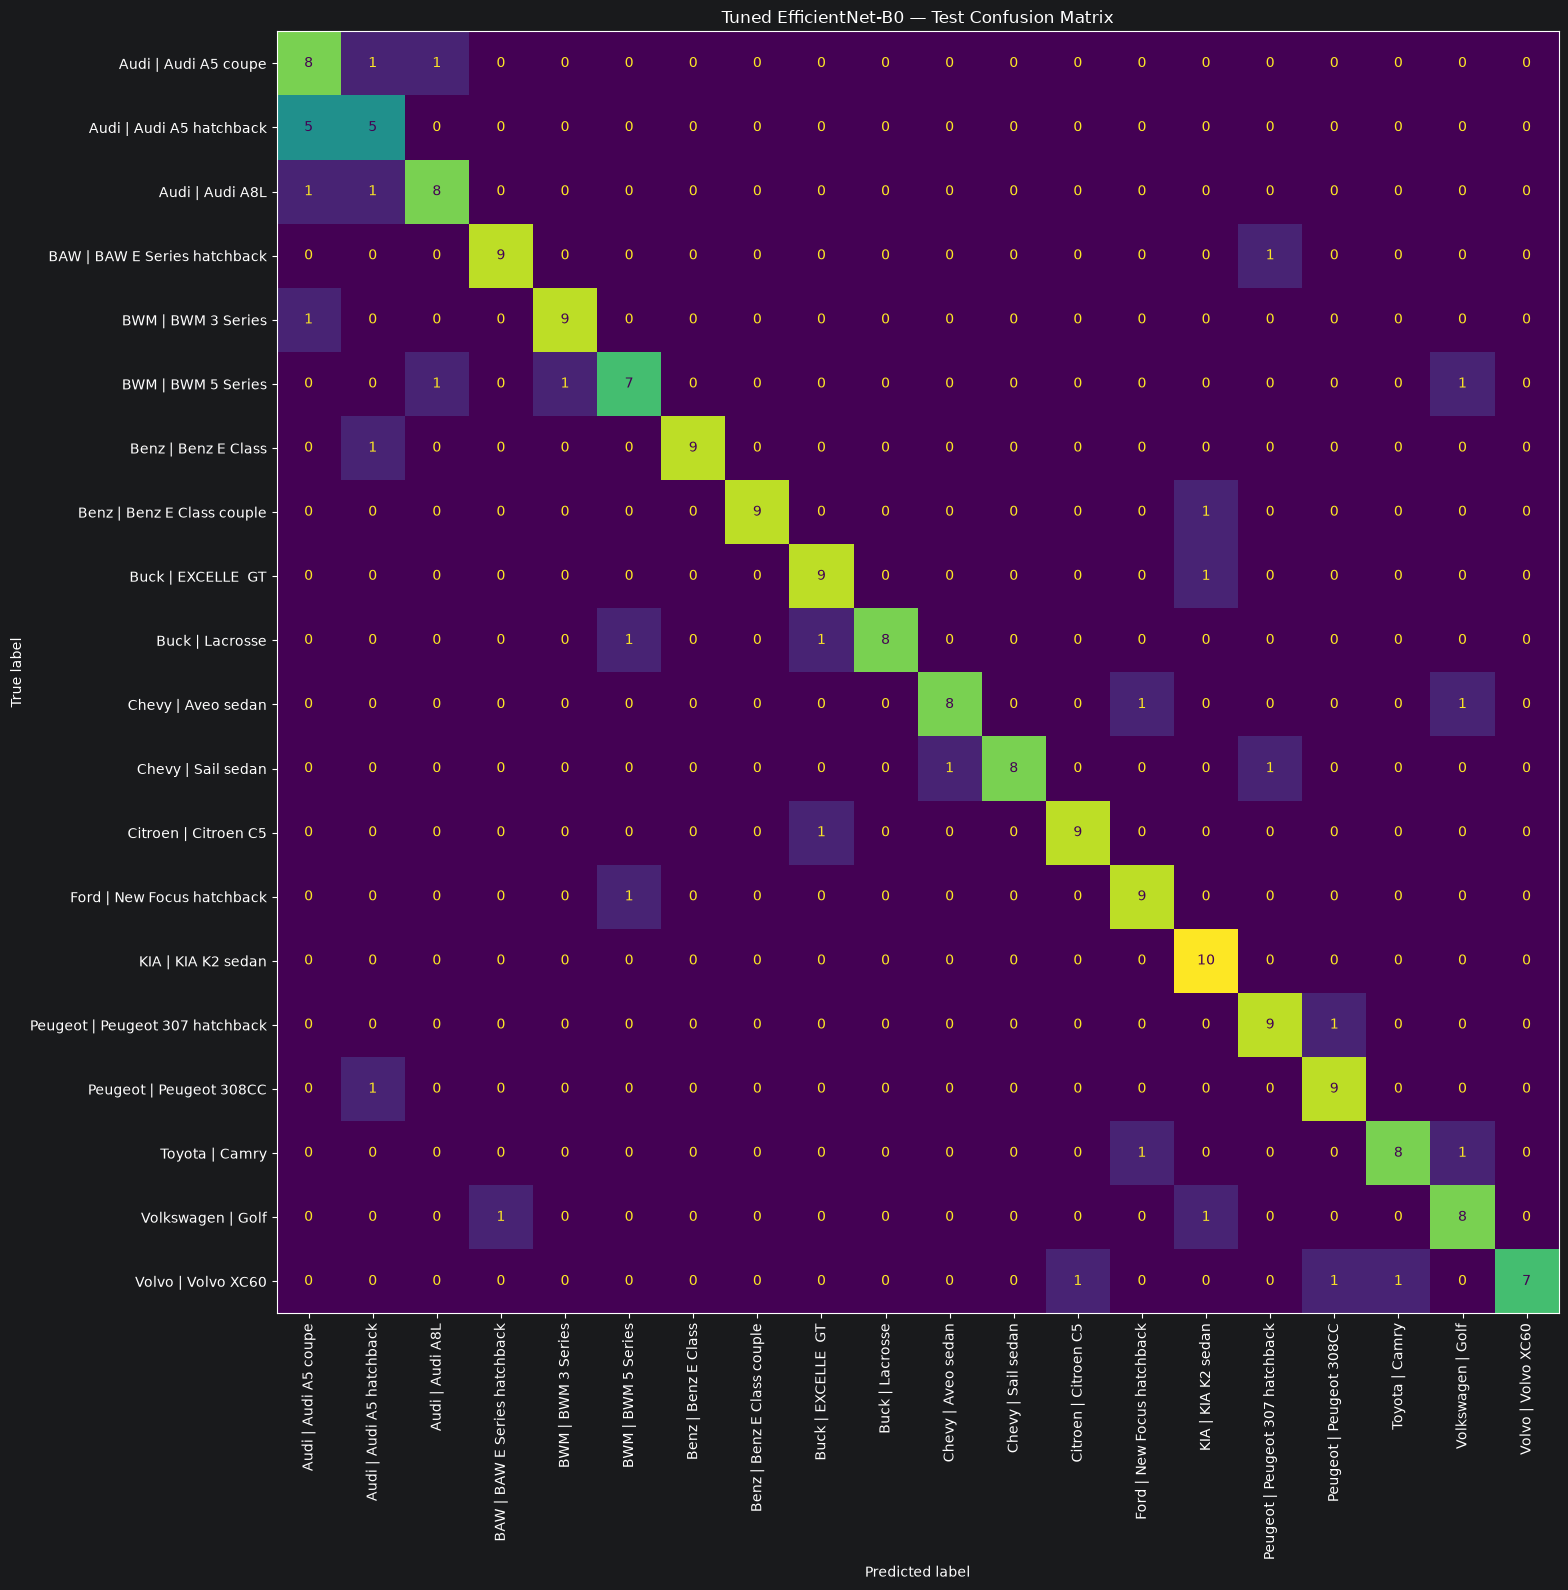

{'architecture': 'EfficientNet-B0', 'best_config': {'name': 'longer_finetune', 'finetune_lr': 0.0001, 'weight_decay': 0.0001, 'unfreeze_depth': 'last_2_stages', 'label_smoothing': 0.1, 'augmentation': 'standard', 'stage2_epochs': 7}, 'validation_top1': 0.775, 'test_top1': 0.83, 'test_top5': 0.98, 'test_macro_f1': 0.8321726930283937, 'gpu': 'NVIDIA GeForce RTX 5060 Laptop GPU'}


In [12]:
report_df = pd.DataFrame(
    classification_report(
        y_true,
        y_pred,
        labels=list(
            range(NUM_CLASSES)
        ),
        target_names=class_names,
        output_dict=True,
        zero_division=0,
    )
).T

display(
    report_df
)

report_df.to_csv(
    REPORT_DIR
    / "best_config_classification_report.csv"
)

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(
        range(NUM_CLASSES)
    ),
)

fig, ax = plt.subplots(
    figsize=(16, 16)
)

ConfusionMatrixDisplay(
    cm,
    display_labels=class_names,
).plot(
    ax=ax,
    xticks_rotation=90,
    colorbar=False,
    values_format="d",
)

ax.set_title(
    "Tuned EfficientNet-B0 — Test Confusion Matrix"
)

plt.tight_layout()

plt.savefig(
    REPORT_DIR
    / "best_config_confusion_matrix.png",
    dpi=160,
)

plt.show()

best_config = {
    "name":str(
        best["name"]
    ),
    "finetune_lr":float(
        best["finetune_lr"]
    ),
    "weight_decay":float(
        best["weight_decay"]
    ),
    "unfreeze_depth":str(
        best["unfreeze_depth"]
    ),
    "label_smoothing":float(
        best["label_smoothing"]
    ),
    "augmentation":str(
        best["augmentation"]
    ),
    "stage2_epochs":int(
        best["stage2_epochs"]
    ),
}

metrics = {
    "architecture":"EfficientNet-B0",
    "best_config":best_config,
    "validation_top1":float(
        best["validation_top1"]
    ),
    "test_top1":float(
        top1
    ),
    "test_top5":float(
        top5
    ),
    "test_macro_f1":float(
        macro_f1
    ),
    "gpu":GPU_NAME,
}

torch.save(
    {
        **metrics,
        "state_dict":model.state_dict(),
        "classes":class_names,
        "num_classes":NUM_CLASSES,
    },
    MODEL_DIR
    / "efficientnet_b0_best_tuned.pt",
)

with (
    REPORT_DIR
    / "best_config_metrics.json"
).open(
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        metrics,
        f,
        indent=2,
    )

print(metrics)